In [77]:
!pip install --no-deps scprep
!pip install --no-deps umap-learn

In [78]:
import pandas as pd
import numpy as np
import scprep, umap
import matplotlib.pyplot as plt
%matplotlib inline

In [79]:
lung = scprep.io.load_csv("Lung-counts.csv", cell_axis='row', sparse=True).transpose()
trachea = scprep.io.load_csv("Trachea-counts.csv", cell_axis='row', sparse=True).transpose()

print("Lung shape:", lung.shape)
display(lung.head())

print("Trachea shape:", trachea.shape)
display(trachea.head())

Lung shape: (1923, 23433)


,0610005C13Rik,0610007C21Rik,0610007L01Rik,0610007N19Rik,0610007P08Rik,0610007P14Rik,0610007P22Rik,0610008F07Rik,0610009B14Rik,0610009B22Rik,...,Zxdb,Zxdc,Zyg11a,Zyg11b,Zyx,Zzef1,Zzz3,a,l7Rn6,zsGreen_transgene
A7.MAA000526.3_9_M.1.1,0.0,310.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
B12.MAA000526.3_9_M.1.1,0.0,200.0,45.0,119.0,0.0,185.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,365.0,18.0,48.0,0.0,0.0,0.0
D4.MAA000526.3_9_M.1.1,0.0,0.0,0.0,0.0,0.0,17.0,0.0,0.0,0.0,55.0,...,0.0,213.0,0.0,0.0,129.0,0.0,0.0,0.0,44.0,0.0
E11.MAA000526.3_9_M.1.1,0.0,485.0,1.0,81.0,117.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,280.0,0.0,0.0,0.0,0.0,0.0
G6.MAA000526.3_9_M.1.1,0.0,546.0,0.0,0.0,0.0,16.0,0.0,0.0,0.0,86.0,...,38.0,0.0,0.0,327.0,220.0,0.0,0.0,0.0,0.0,0.0


Trachea shape: (1391, 23433)


,0610005C13Rik,0610007C21Rik,0610007L01Rik,0610007N19Rik,0610007P08Rik,0610007P14Rik,0610007P22Rik,0610008F07Rik,0610009B14Rik,0610009B22Rik,...,Zxdb,Zxdc,Zyg11a,Zyg11b,Zyx,Zzef1,Zzz3,a,l7Rn6,zsGreen_transgene
A7.D042474.3_8_M.1.1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,20.0,0.0,84.0,0.0,0.0,0.0
B21.D042474.3_8_M.1.1,0.0,135.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,115.0,0.0,306.0,0.0,0.0,0.0,0.0,0.0,0.0
D16.D042474.3_8_M.1.1,0.0,4.0,85.0,0.0,51.0,0.0,0.0,0.0,0.0,0.0,...,7.0,0.0,0.0,0.0,224.0,3.0,8.0,0.0,0.0,0.0
F10.D042474.3_8_M.1.1,0.0,135.0,136.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
H14.D042474.3_8_M.1.1,0.0,318.0,251.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,269.0,0.0,247.0,0.0,73.0,0.0


In [80]:
data = [lung, trachea]
batch_labels = ['Lung', 'Trachea']

data, sample_labels = scprep.utils.combine_batches(data, batch_labels)

In [81]:
print("Combined data shape:", data.shape)
print("First 10 genes (columns):", data.columns[:10].tolist())
print("First 10 cells (index):", data.index[:10].tolist())

Combined data shape: (3314, 23433)
First 10 genes (columns): ['0610005C13Rik', '0610007C21Rik', '0610007L01Rik', '0610007N19Rik', '0610007P08Rik', '0610007P14Rik', '0610007P22Rik', '0610008F07Rik', '0610009B14Rik', '0610009B22Rik']
First 10 cells (index): ['A7.MAA000526.3_9_M.1.1_Lung', 'B12.MAA000526.3_9_M.1.1_Lung', 'D4.MAA000526.3_9_M.1.1_Lung', 'E11.MAA000526.3_9_M.1.1_Lung', 'G6.MAA000526.3_9_M.1.1_Lung', 'H14.MAA000526.3_9_M.1.1_Lung', 'J4.MAA000526.3_9_M.1.1_Lung', 'K21.MAA000526.3_9_M.1.1_Lung', 'M10.MAA000526.3_9_M.1.1_Lung', 'A8.MAA000526.3_9_M.1.1_Lung']


In [82]:
lookup = pd.Series(data.index).apply(lambda x: x.split('.')[1])
metadata = pd.read_csv('metadata_FACS.csv', index_col=0).loc[lookup.values].reset_index()
metadata.index = data.index
metadata.head()

,plate.barcode,mouse.id,tissue,subtissue,FACS.selection,mouse.sex
A7.MAA000526.3_9_M.1.1_Lung,MAA000526,3_9_M,Lung,NaN,Multiple,M
B12.MAA000526.3_9_M.1.1_Lung,MAA000526,3_9_M,Lung,NaN,Multiple,M
D4.MAA000526.3_9_M.1.1_Lung,MAA000526,3_9_M,Lung,NaN,Multiple,M
E11.MAA000526.3_9_M.1.1_Lung,MAA000526,3_9_M,Lung,NaN,Multiple,M
G6.MAA000526.3_9_M.1.1_Lung,MAA000526,3_9_M,Lung,NaN,Multiple,M


<Axes: title={'center': 'Library size before filtering'}, xlabel='Library size', ylabel='Number of cells'>

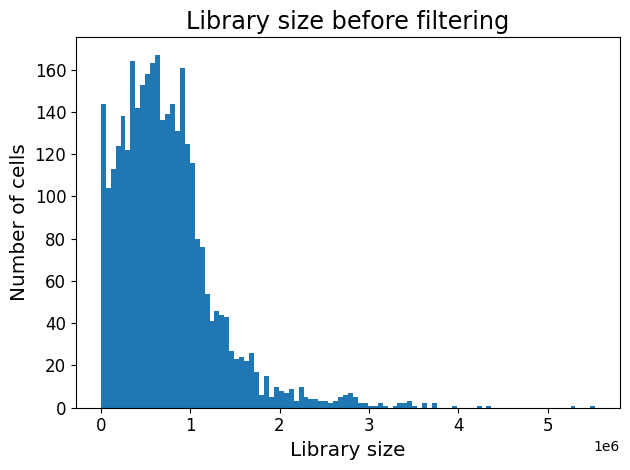

In [83]:
scprep.plot.plot_library_size(data, log=False, title='Library size before filtering')

<Axes: title={'center': 'Library size with chosen percentiles'}, xlabel='Library size', ylabel='Number of cells'>

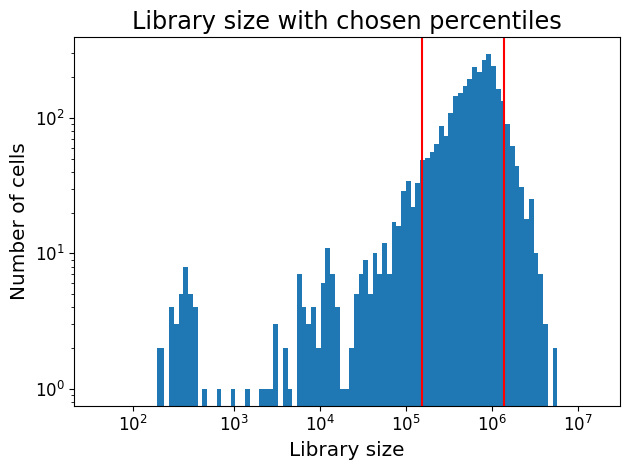

In [84]:
percentiles = (10, 90)
scprep.plot.plot_library_size(data, percentile=percentiles, title="Library size with chosen percentiles")

In [85]:
data, metadata = scprep.filter.filter_library_size(data, metadata, percentile=percentiles)

<Axes: title={'center': 'Gene capture before filtering'}, xlabel='# of cells with nonzero expression', ylabel='# of genes'>

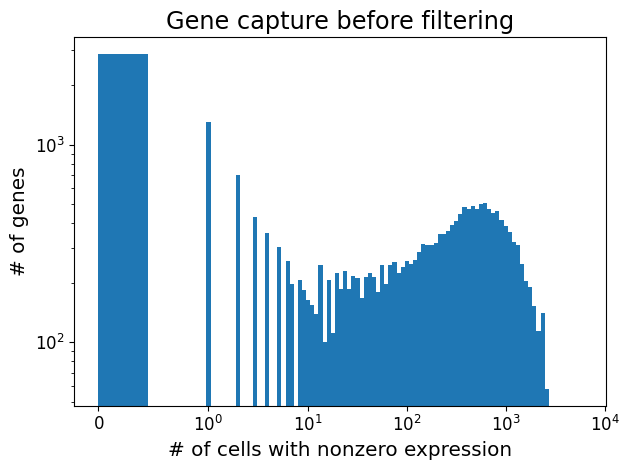

In [86]:
scprep.plot.histogram(scprep.measure.gene_capture_count(data), log=True,
                      title="Gene capture before filtering",
                      xlabel='# of cells with nonzero expression',
                      ylabel='# of genes')

In [87]:
cutoff = 10
data = scprep.filter.filter_rare_genes(data, min_cells=cutoff)

<Axes: title={'center': 'Gene capture after filtering'}, xlabel='# of cells with nonzero expression', ylabel='# of genes'>

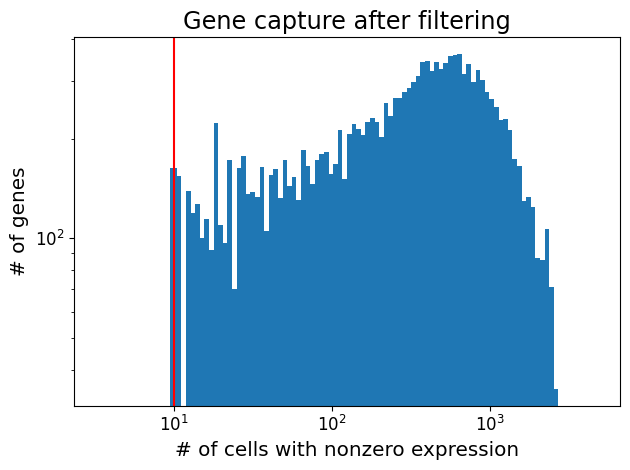

In [88]:
scprep.plot.histogram(scprep.measure.gene_capture_count(data),
                      cutoff = cutoff,
                      log=True,
                      title="Gene capture after filtering",
                      xlabel='# of cells with nonzero expression',
                      ylabel='# of genes')

In [89]:
print("After gene filtering: data.shape =", data.shape)

After gene filtering: data.shape = (2650, 16619)


<Axes: title={'center': 'Library size after normalization'}, xlabel='Library size', ylabel='Number of cells'>

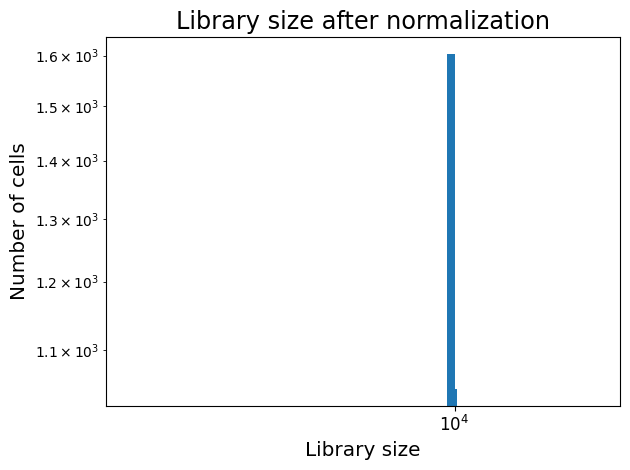

In [90]:
data, metadata['library_size'] = scprep.normalize.library_size_normalize(data, return_library_size=True)
scprep.plot.plot_library_size(data, title='Library size after normalization')

<Axes: title={'center': 'Distribution of Mean Gene Expression (before transform)'}, xlabel='Mean Expression per Gene', ylabel='Number of Genes'>

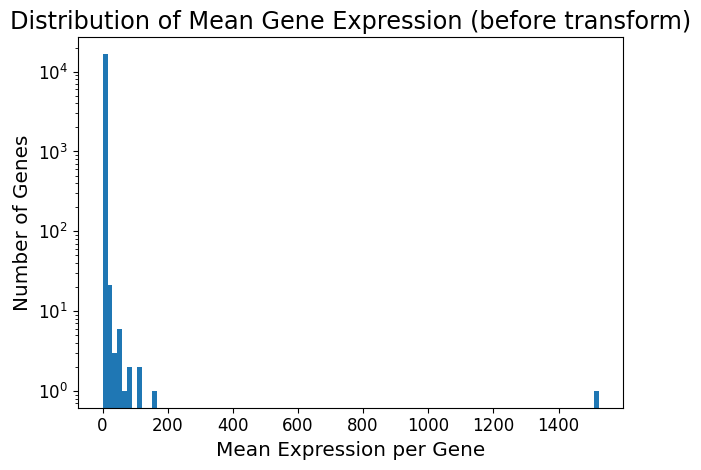

In [91]:
scprep.plot.histogram(data.mean(axis=0), log='y',
                      title= "Distribution of Mean Gene Expression (before transform)",
                      xlabel= "Mean Expression per Gene",
                      ylabel= "Number of Genes")

In [92]:
data = scprep.transform.sqrt(data)

<Axes: title={'center': 'Distribution of Mean Gene Expression (Square Root Transformed)'}, xlabel='Mean Expression per Gene (Square root scale)', ylabel='Number of Genes'>

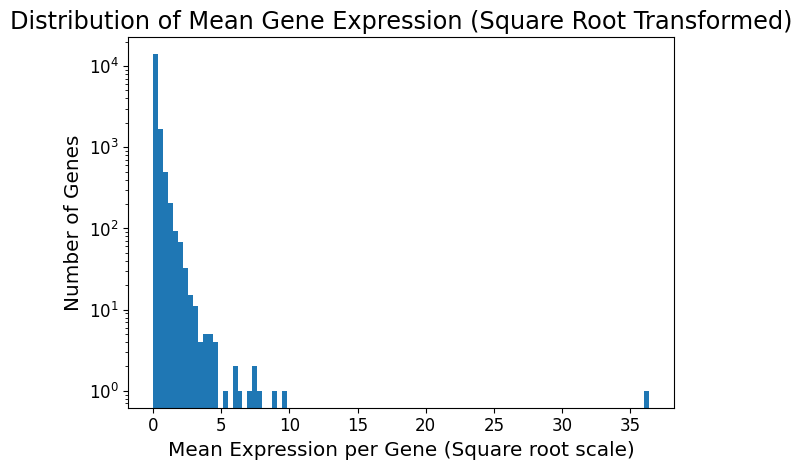

In [93]:
scprep.plot.histogram(data.mean(axis=0), log='y',
                      title= "Distribution of Mean Gene Expression (Square Root Transformed)",
                      xlabel= "Mean Expression per Gene (Square root scale)",
                      ylabel= "Number of Genes")

In [94]:
data.to_pickle("data.pickle.gz")
metadata.to_pickle("metadata.pickle.gz")

print("Saved data.pickle.gz and metadata.pickle.gz to working directory.")

Saved data.pickle.gz and metadata.pickle.gz to working directory.


In [95]:
import umap
import os

In [96]:
data_pca = scprep.reduce.pca(data, n_components=50, method='dense')
display(data_pca.head())

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,...,PC41,PC42,PC43,PC44,PC45,PC46,PC47,PC48,PC49,PC50
A7.MAA000526.3_9_M.1.1_Lung,-9.070698,9.698608,27.006181,0.712281,-0.909099,7.895891,0.073102,6.850431,1.763772,-3.457871,...,1.113263,0.214980,2.156906,2.080013,0.677694,2.909797,1.394645,-0.673706,6.458324,-1.327777
D4.MAA000526.3_9_M.1.1_Lung,-3.131412,20.055049,-1.552468,1.920350,19.270258,54.589380,-3.615651,6.505970,0.514384,-2.299856,...,-0.958190,-0.310858,-2.027896,0.941012,-1.114038,-1.622852,-0.630024,-1.293386,0.081483,-1.177206
G6.MAA000526.3_9_M.1.1_Lung,-23.433057,-24.557601,-2.592187,16.509013,-4.950259,3.640718,3.522974,8.591292,-6.937087,-2.053744,...,1.677686,-2.946133,-0.408640,-1.300783,0.659199,-1.691855,1.832893,-1.558058,-0.072539,2.488885
H14.MAA000526.3_9_M.1.1_Lung,27.278687,-18.368961,-1.014084,-11.884419,-6.959289,7.548708,-3.191774,-3.105767,2.044831,-2.550706,...,1.974528,3.059655,-0.155819,-6.529250,-0.230837,-1.299868,3.085249,-2.083924,1.111275,0.995043
J4.MAA000526.3_9_M.1.1_Lung,-8.155976,19.806087,-10.571087,6.633196,24.256428,49.775890,-10.086841,2.589095,-5.785596,-5.521169,...,0.019550,-0.120432,-1.724850,-0.882725,-0.320396,1.104364,-0.194711,0.745331,-1.023701,0.274604


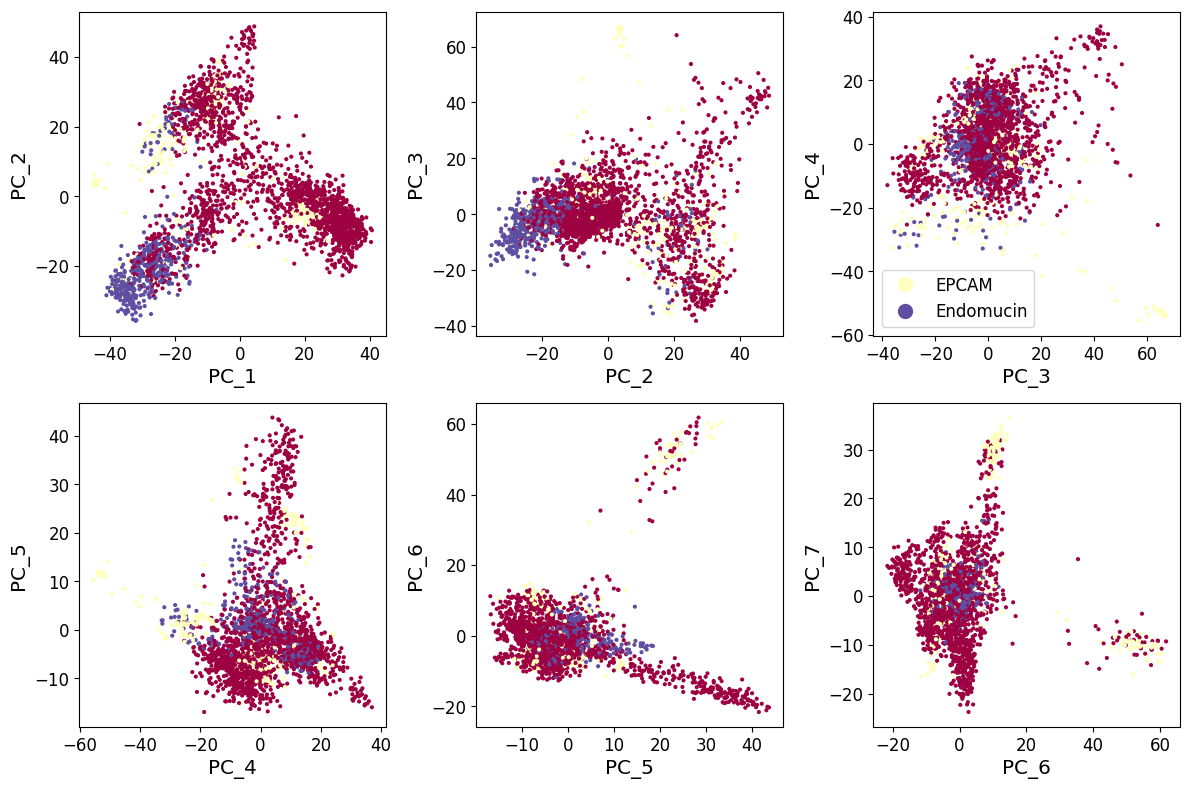

In [97]:
fig, axes = plt.subplots(2,3, figsize=(12,8))
axes = axes.flatten()

for i, ax in enumerate(axes):
    legend = True if i == 2 else False
    scprep.plot.scatter(data_pca.iloc[:,i], data_pca.iloc[:,i+1],
                        c=metadata.get('subtissue', pd.Series(['NA']*len(metadata))),
                        cmap='Spectral', ax=ax,
                        xlabel="PC_" + str(i+1), ylabel="PC_" + str(i+2), legend=legend)
fig.tight_layout()

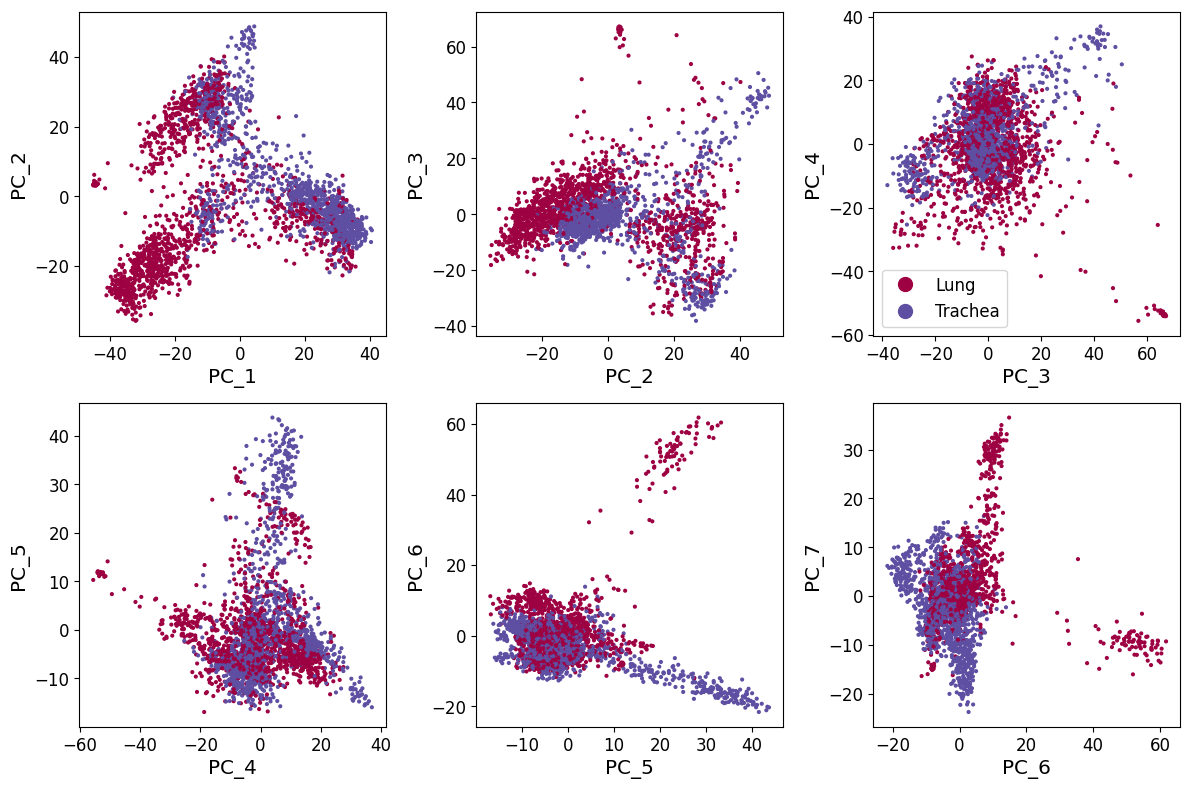

In [98]:
fig, axes = plt.subplots(2,3, figsize=(12,8))
axes = axes.flatten()

for i, ax in enumerate(axes):
    legend = True if i == 2 else False
    scprep.plot.scatter(data_pca.iloc[:,i], data_pca.iloc[:,i+1],
                        c=metadata['tissue'],
                        cmap='Spectral', ax=ax,
                        xlabel="PC_" + str(i+1), ylabel="PC_" + str(i+2), legend=legend)
fig.tight_layout()

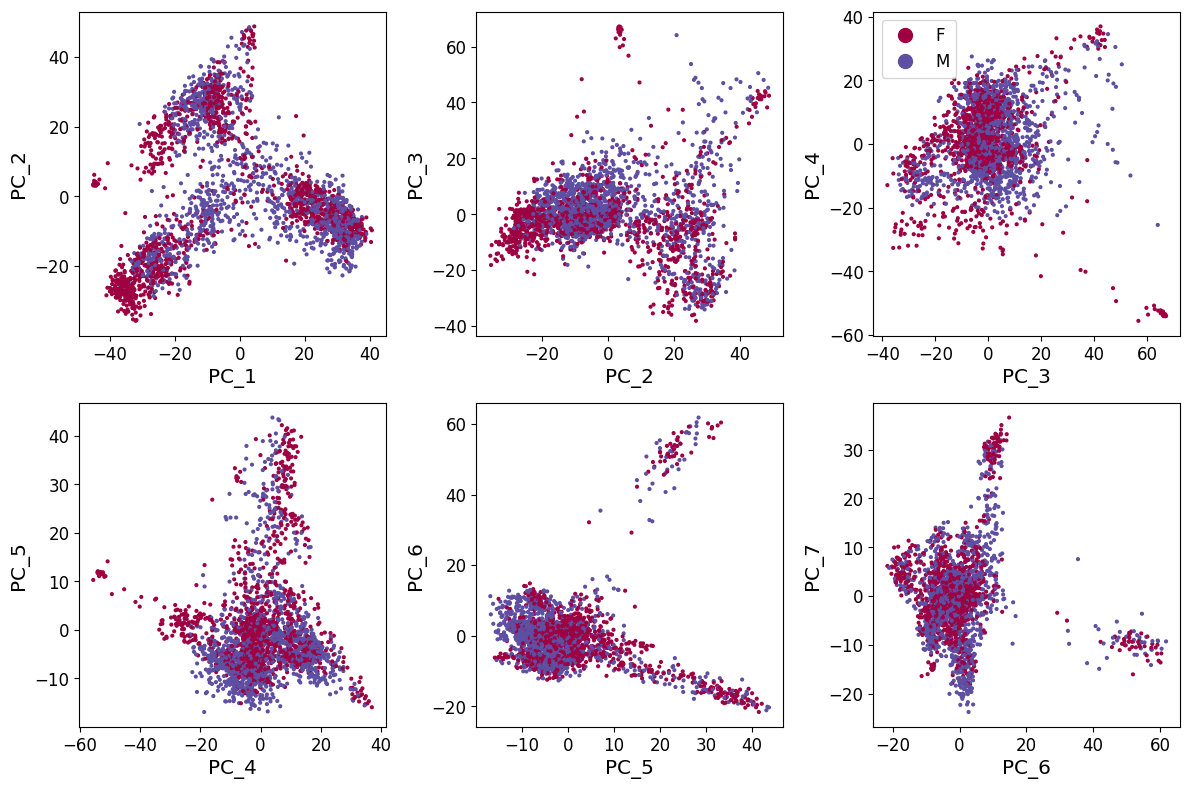

In [99]:
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
axes = axes.flatten()

for i, ax in enumerate(axes):
  legend = True if i == 2 else False
  scprep.plot.scatter(
      data_pca.iloc[:, i], data_pca.iloc[:, i+1],
      c=metadata['mouse.sex'],
      cmap='Spectral',
      ax=ax,
      xlabel="PC_" + str(i+1),
      ylabel="PC_" + str(i+2),
      legend=legend
  )
fig.tight_layout()

<Axes: title={'center': 'Actb'}, xlabel='PC1', ylabel='PC2'>

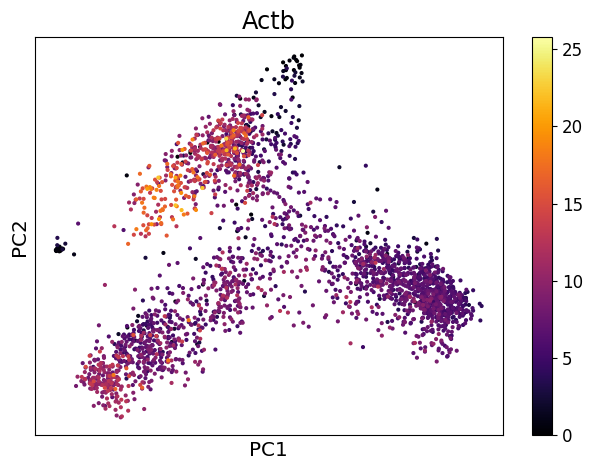

In [100]:
expression = scprep.select.select_cols(data, exact_word='Actb')
sort_index = expression.sort_values().index
scprep.plot.scatter2d(data_pca.loc[sort_index], c=expression.loc[sort_index], shuffle=False,
                      title='Actb', ticks=None, label_prefix='PC')

<Axes: title={'center': 'B2m'}, xlabel='PC1', ylabel='PC2'>

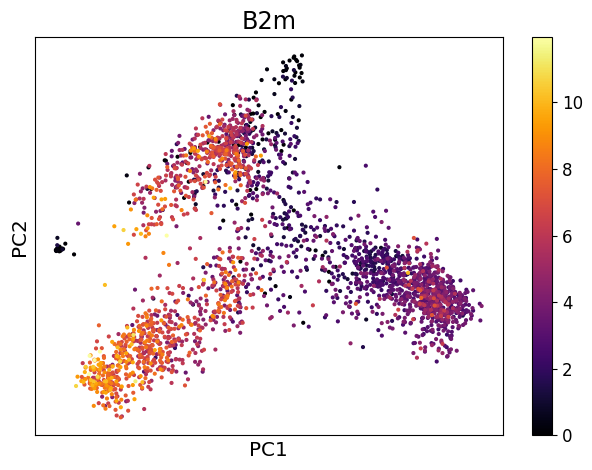

In [101]:
expression = scprep.select.select_cols(data, exact_word='B2m')
sort_index = expression.sort_values().index
scprep.plot.scatter2d(data_pca.loc[sort_index], c=expression.loc[sort_index], shuffle=False,
                      title='B2m', ticks=None, label_prefix='PC')

<Axes: xlabel='UMAP1', ylabel='UMAP2'>

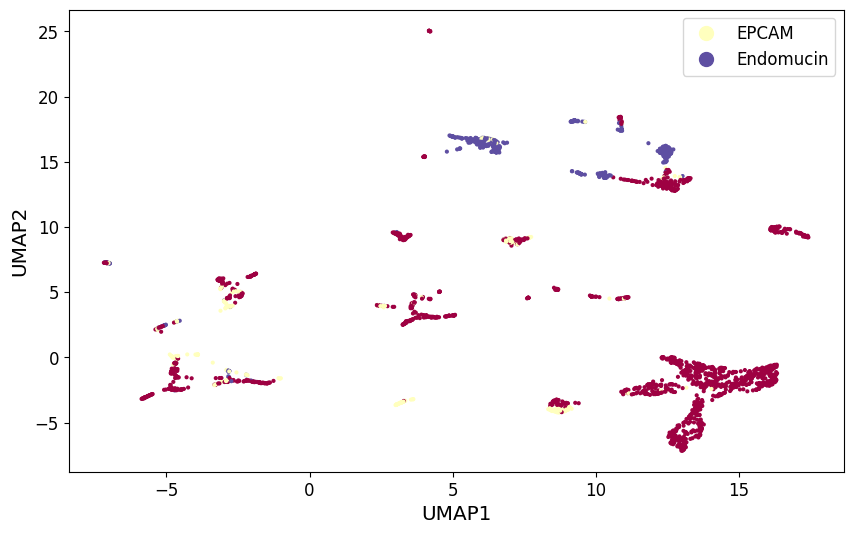

In [102]:
data_umap = umap.UMAP().fit_transform(data_pca.iloc[:,:50])
data_umap = pd.DataFrame(data_umap, index = data.index)

fig, ax = plt.subplots(figsize=(10,6))
scprep.plot.scatter2d(data_umap, cmap='Spectral', c=metadata['subtissue'], ax=ax, label_prefix="UMAP")

<Axes: xlabel='UMAP1', ylabel='UMAP2'>

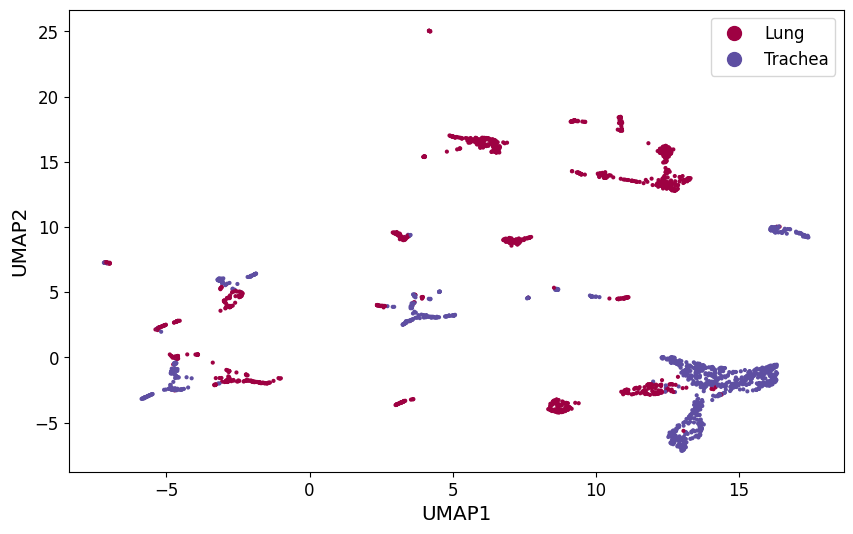

In [103]:
fig, ax = plt.subplots(figsize=(10,6))
scprep.plot.scatter2d(data_umap, cmap='Spectral', c=metadata['tissue'], ax=ax, label_prefix="UMAP")

<Axes: xlabel='UMAP1', ylabel='UMAP2'>

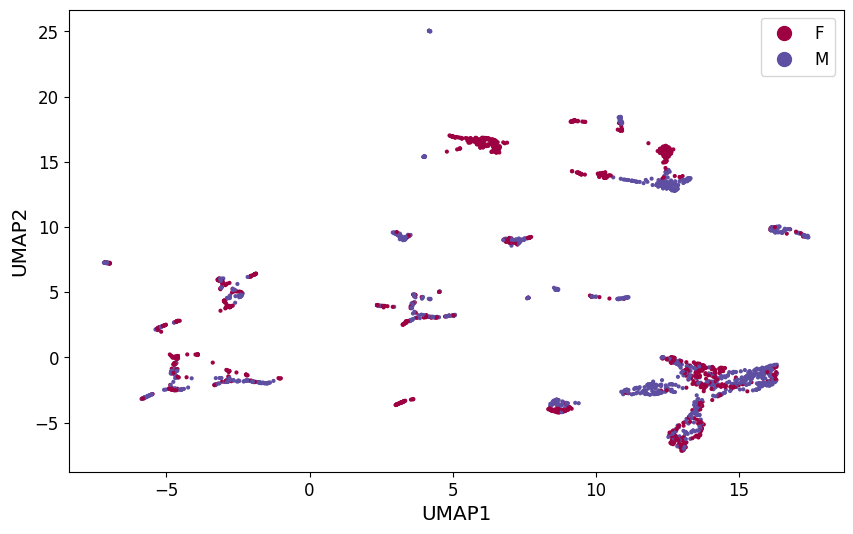

In [104]:
fig, ax = plt.subplots(figsize=(10,6))
scprep.plot.scatter2d(data_umap, cmap='Spectral', c=metadata['mouse.sex'], ax=ax, label_prefix="UMAP")

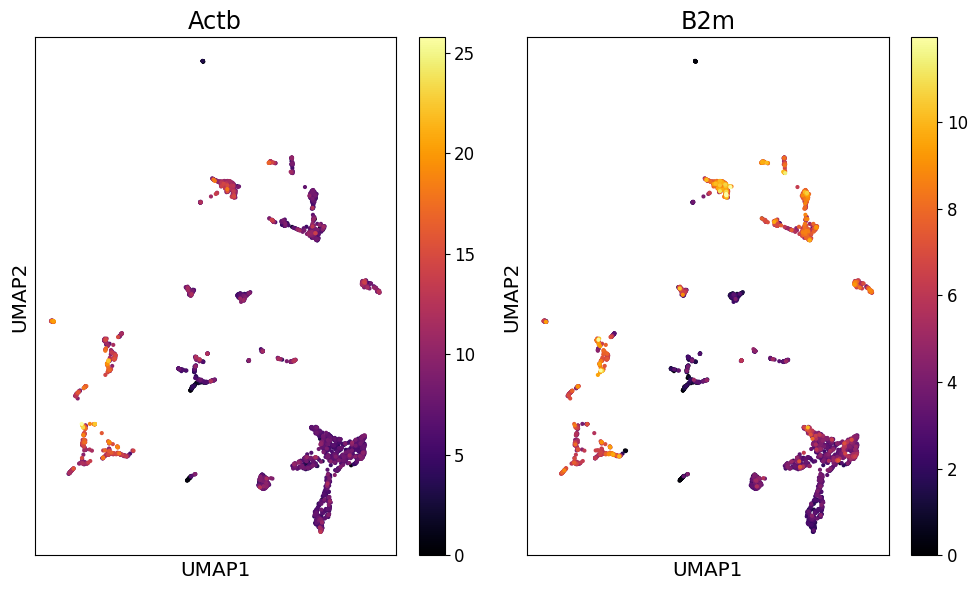

In [105]:
genes_for_plotting = ['Actb', 'B2m']
fig, axes = plt.subplots(1, 2, figsize=(10,6))

for gene, ax in zip(genes_for_plotting, axes.flatten()):
    expression = scprep.select.select_cols(data, exact_word=gene)
    sort_index = expression.sort_values().index

    scprep.plot.scatter2d(data_umap.loc[sort_index], c=expression.loc[sort_index],
                          shuffle=False, title=gene, label_prefix='UMAP', ticks=None, ax=ax)
fig.tight_layout()

In [106]:
!pip install --no-deps scprep
!pip install --no-deps umap-learn
!pip install phenograph
!pip install --no-deps tasklogger
!pip install graphtools

In [107]:
import pandas as pd
import numpy as np
import scprep, umap
import sklearn
import sklearn.cluster
import sklearn.manifold
import graphtools as gt
import phenograph
import matplotlib.pyplot as plt
import tasklogger
import seaborn as sns

%matplotlib inline

In [108]:
data = pd.read_pickle('data.pickle.gz')
metadata = pd.read_pickle('metadata.pickle.gz')

data_pca = scprep.reduce.pca(data, n_components=50, method='dense')

<Axes: title={'center': 'Actb'}, xlabel='PC1', ylabel='PC2'>

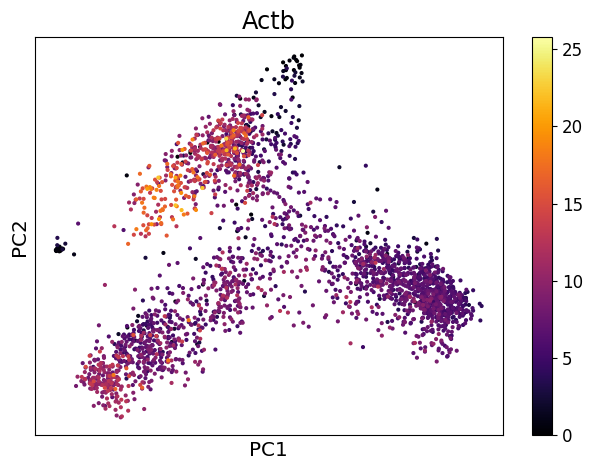

In [109]:
expression = scprep.select.select_cols(data, exact_word='Actb')
sort_index = expression.sort_values().index
scprep.plot.scatter2d(data_pca.loc[sort_index],
                          c=expression.loc[sort_index],
                          shuffle=False,
                          title='Actb',
                          ticks=None,
                          label_prefix='PC')

<Axes: title={'center': 'B2m'}, xlabel='PC1', ylabel='PC2'>

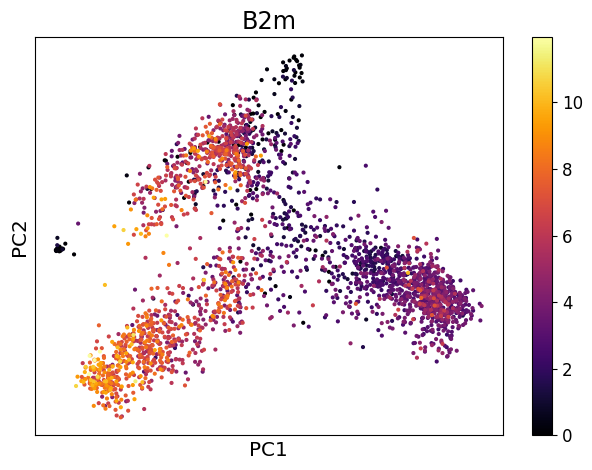

In [110]:
expression = scprep.select.select_cols(data, exact_word='B2m')
sort_index = expression.sort_values().index
scprep.plot.scatter2d(data_pca.loc[sort_index],
                          c=expression.loc[sort_index],
                          shuffle=False,
                          title='B2m',
                          ticks=None,
                          label_prefix='PC')

In [111]:
clusterings = {}

In [112]:
with tasklogger.log_task("phenograph"):
    phenograph_clusters, _, _ = phenograph.cluster(data_pca)
clusterings['Phenograph'] = phenograph_clusters
print("Phenograph clusters shape:", phenograph_clusters.shape)

Calculating phenograph...
Finding 30 nearest neighbors using minkowski metric and 'auto' algorithm
Neighbors computed in 0.3521993160247803 seconds
Jaccard graph constructed in 3.735470771789551 seconds
Wrote graph to binary file in 0.2833080291748047 seconds
Running Louvain modularity optimization
After 1 runs, maximum modularity is Q = 0.926567
After 6 runs, maximum modularity is Q = 0.927789
Louvain completed 26 runs in 1.4977927207946777 seconds
Sorting communities by size, please wait ...
PhenoGraph completed in 6.161584377288818 seconds
Calculated phenograph in 6.17 seconds.
Phenograph clusters shape: (2650,)


In [113]:
with tasklogger.log_task("KMeans"):
    kmeans_clusters = sklearn.cluster.KMeans(n_clusters=10, n_init=10).fit_predict(data_pca)
clusterings['KMeans'] = kmeans_clusters
print("KMeans clusters shape:", kmeans_clusters.shape)

Calculating KMeans...
Calculated KMeans in 0.53 seconds.
KMeans clusters shape: (2650,)


In [114]:
G = gt.Graph(data_pca)

with tasklogger.log_task("Spectral clustering"):
    spec_op = sklearn.cluster.SpectralClustering(n_clusters=10, affinity='precomputed', assign_labels='kmeans')
    spectral_clusters = spec_op.fit_predict(G.K)
clusterings['Spectral'] = spectral_clusters
print("Spectral clusters shape:", spectral_clusters.shape)

Calculating Spectral clustering...


/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


Calculated Spectral clustering in 1.46 seconds.
Spectral clusters shape: (2650,)


In [115]:
for alg in list(clusterings.keys()):
    cl_nu = scprep.utils.sort_clusters_by_values(clusterings[alg], -data_pca.iloc[:,0])
    clusterings[alg] = cl_nu

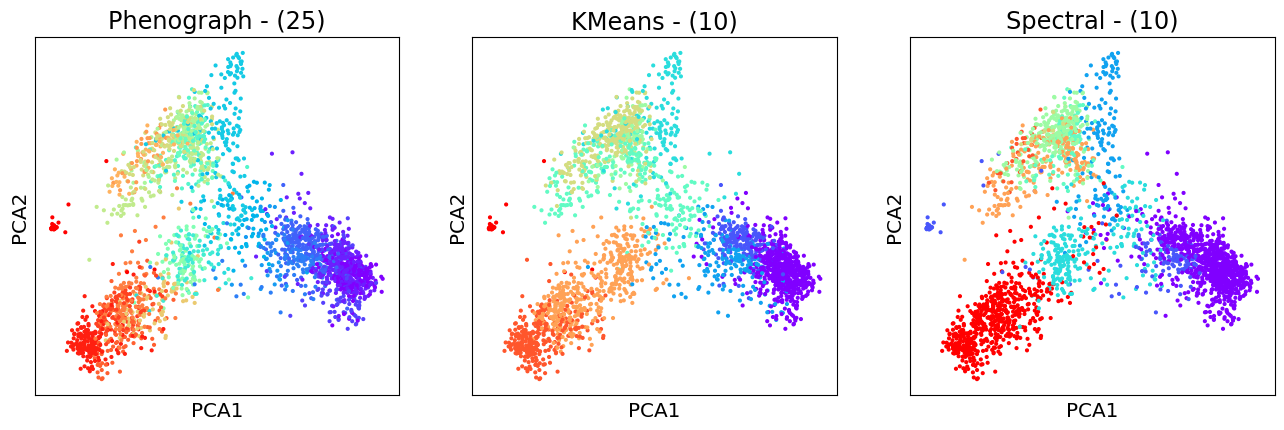

In [116]:
fig, axes = plt.subplots(1,3, figsize=(16,16), subplot_kw={'aspect':'equal'})
for ax, algorithm in zip(axes.flatten(), clusterings):
    scprep.plot.scatter2d(data_pca, c=clusterings[algorithm],
                         cmap=plt.cm.rainbow,
                         title='{} - ({})'.format(algorithm, len(np.unique(clusterings[algorithm]))),
                         ticks=False, label_prefix="PCA", legend=False, discrete=True,
                         ax=ax)
plt.show()

k = 2 prediction strength = 0.3889892713089413 time(s)= 81.79
k = 3 prediction strength = 0.33179603202227637 time(s)= 61.14
k = 4 prediction strength = 0.25800812841669907 time(s)= 60.91
k = 5 prediction strength = 0.21106925192631873 time(s)= 61.43
k = 6 prediction strength = 0.167420814479638 time(s)= 88.35
k = 7 prediction strength = 0.16501078328999544 time(s)= 67.11
k = 8 prediction strength = 0.11625905147997244 time(s)= 68.21
k = 9 prediction strength = 0.14109474280488388 time(s)= 70.07


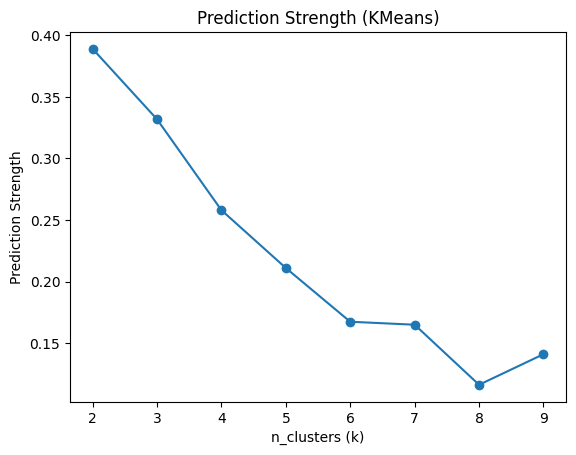

In [117]:
from sklearn.model_selection import train_test_split
from itertools import combinations
from scipy import sparse
import time

def labels_to_mat(labels, n_clusters, N):
    comember = np.zeros((N, N), dtype=bool)
    for i in range(n_clusters):
        match_idx = np.where(labels==i)[0]
        match_idx = iter(combinations(match_idx, 2))
        for (j,k) in match_idx:
            comember[j,k] = True
    comember = np.maximum(comember, comember.transpose())
    comember[np.diag_indices_from(comember)] = True
    comember = sparse.csr_matrix(comember)
    return comember

def get_comemberships(dat, n_clusters, model, kwargs={}):
    model = model(n_clusters=n_clusters, **kwargs)
    model.fit(dat)
    labels = model.predict(dat)
    comember = labels_to_mat(labels, n_clusters, N=dat.shape[0])
    return comember, model

def prediction_strength(full_dat, n_clusters, n_CV=3, verbose=False, model=sklearn.cluster.KMeans, kwargs={}):
    test_size = 1./n_CV
    res = []
    for i in range(n_CV):
        train_dat, test_dat = train_test_split(full_dat, test_size=test_size)
        N_test = test_dat.shape[0]
        __, train_model  = get_comemberships(train_dat, n_clusters, model=model, kwargs=kwargs)
        ground_truth, __ = get_comemberships(test_dat, n_clusters, model=model, kwargs=kwargs)
        pred_labels = labels_to_mat(train_model.predict(test_dat), n_clusters, N_test)
        match_count = ground_truth.minimum(pred_labels).sum()
        res.append(match_count/(N_test**2))
    if verbose:
        print(res)
    return np.mean(res)

start = 2
end = 10
pred_strengths = []
for k in range(start, end):
    t0 = time.time()
    ps = prediction_strength(full_dat=data, n_clusters=k, n_CV=3, model=sklearn.cluster.KMeans, kwargs={})
    t1 = time.time()
    pred_strengths.append(ps)
    print("k =", k, "prediction strength =", ps, "time(s)=", round(t1-t0,2))

n_clusters = list(range(start, end))
plt.plot(n_clusters, pred_strengths, marker='o')
plt.xlabel("n_clusters (k)")
plt.ylabel("Prediction Strength")
plt.title("Prediction Strength (KMeans)")
plt.show()

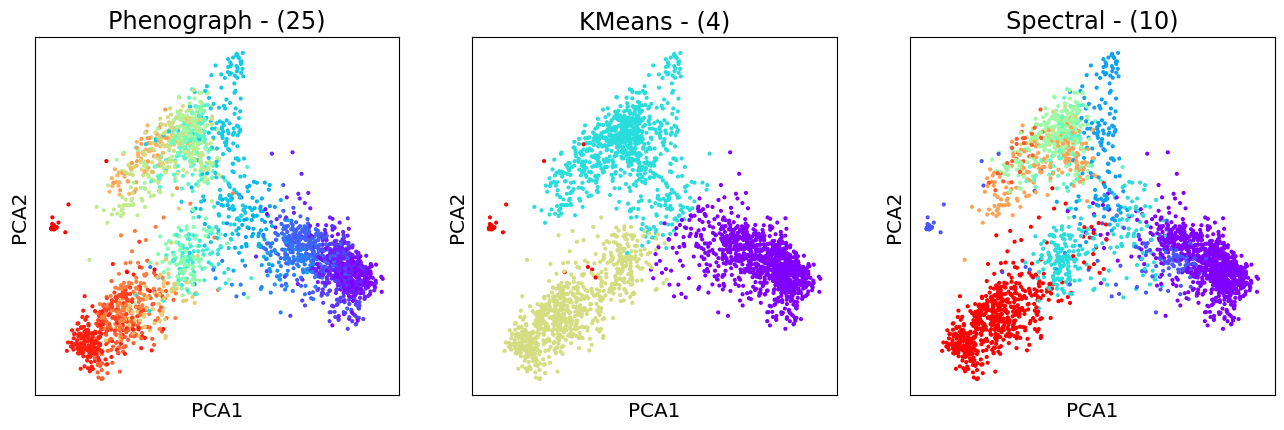

In [118]:
optimal_n_clusters = 4

kmeans_clusters = sklearn.cluster.KMeans(n_clusters=optimal_n_clusters, n_init=10).fit_predict(data_pca)
clusterings['KMeans'] = kmeans_clusters

for alg in list(clusterings.keys()):
    cl_nu = scprep.utils.sort_clusters_by_values(clusterings[alg], -data_pca.iloc[:,0])
    clusterings[alg] = cl_nu

fig, axes = plt.subplots(1,3, figsize=(16,16), subplot_kw={'aspect':'equal'})
for ax, algorithm in zip(axes.flatten(), clusterings):
    scprep.plot.scatter2d(data_pca, c=clusterings[algorithm],
                         cmap=plt.cm.rainbow,
                         title='{} - ({})'.format(algorithm, len(np.unique(clusterings[algorithm]))),
                         ticks=False, label_prefix="PCA", legend=False, discrete=True,
                         ax=ax)
plt.show()

In [119]:
all_clusterings = []
all_algorithms = list(clusterings.keys())
for algo in all_algorithms:
    all_clusterings.append(clusterings[algo])
all_clusterings = np.vstack(all_clusterings)

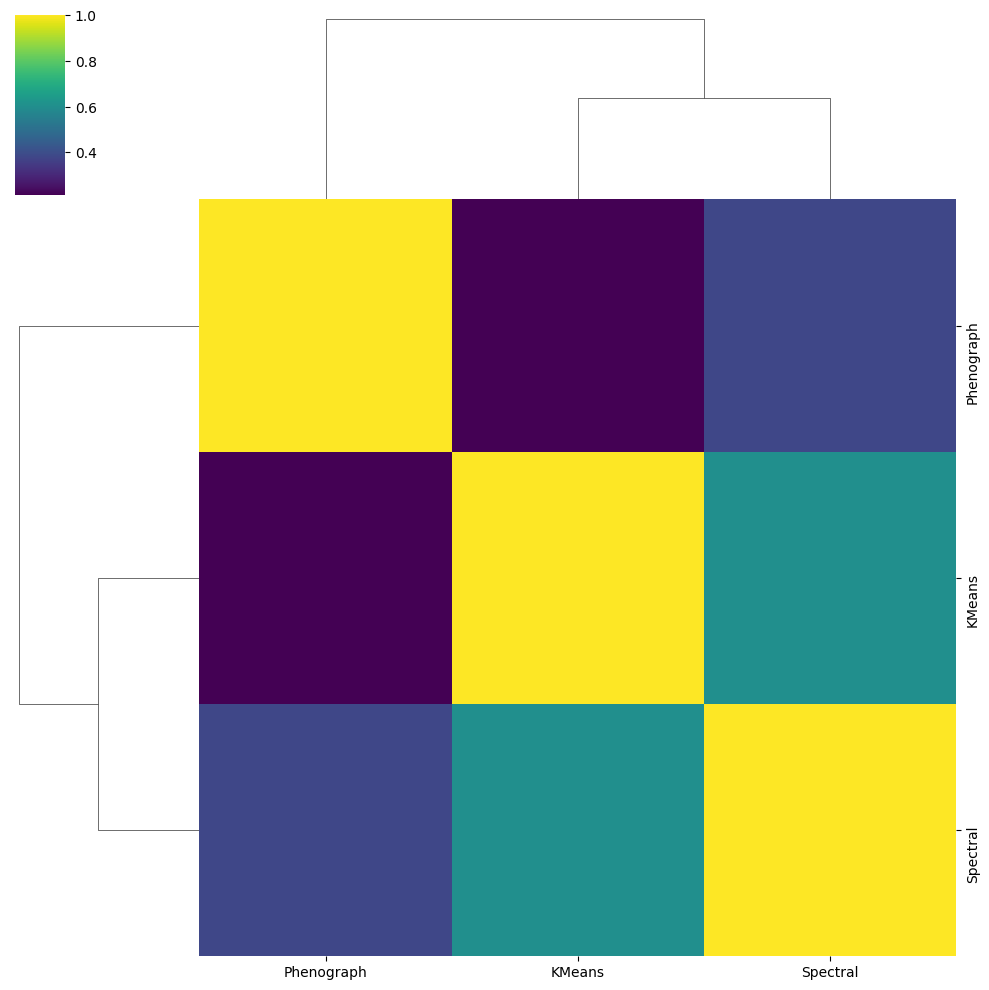

In [120]:
from scipy.spatial.distance import pdist, squareform
cluster_similarities = squareform(pdist(all_clusterings, metric=sklearn.metrics.adjusted_rand_score))
cluster_similarities = cluster_similarities + np.eye(len(all_algorithms))  # fix diagonals

sns.clustermap(cluster_similarities, xticklabels=all_algorithms, yticklabels=all_algorithms, cmap='viridis')
plt.show()

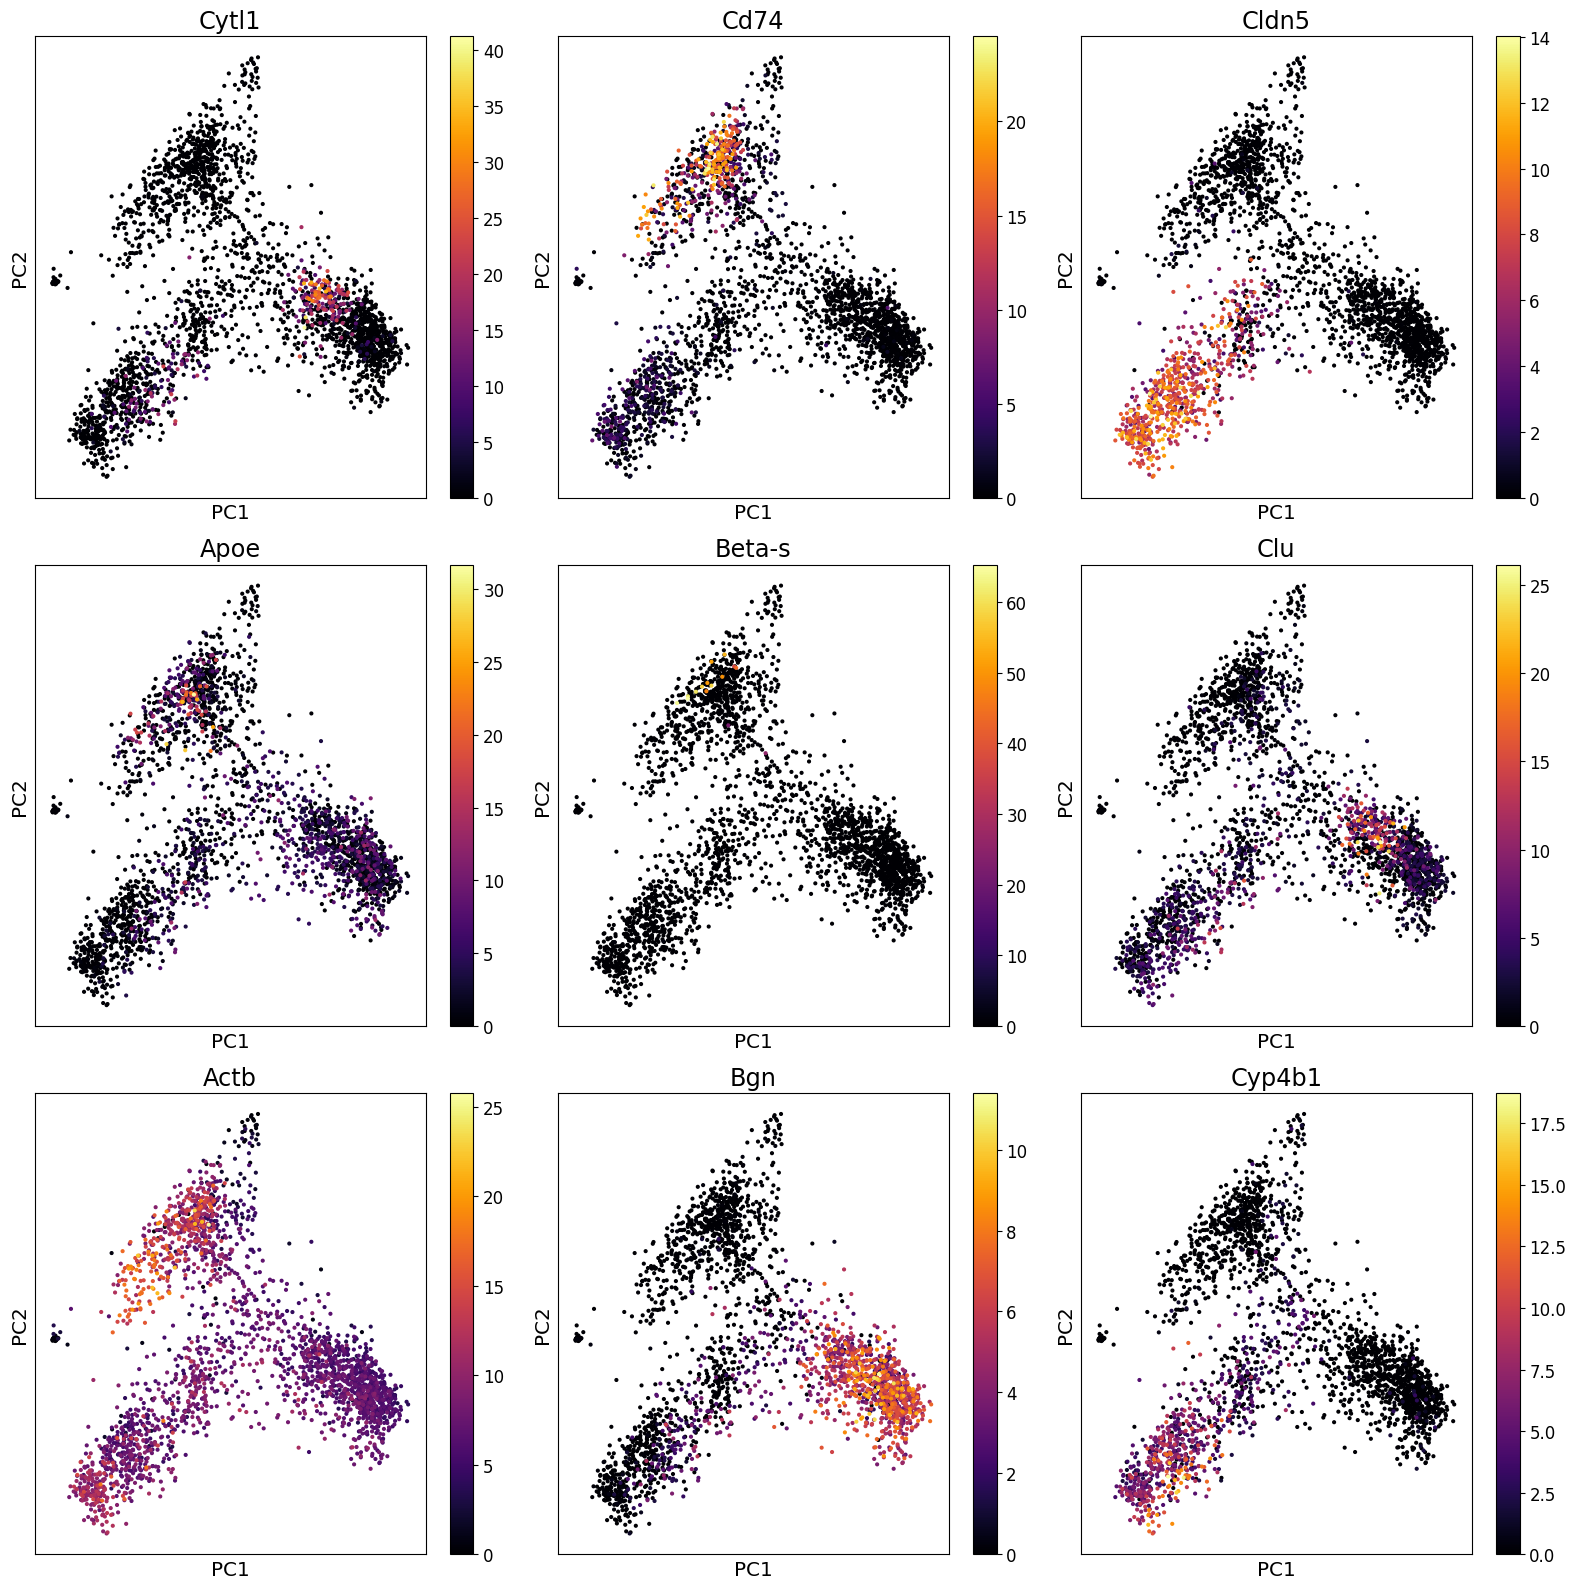

In [121]:
gene_list = ['Cytl1', 'Cd74', 'Cldn5', 'Apoe', 'Beta-s', 'Clu', 'Actb', 'Bgn', 'Cyp4b1']

fig, axes = plt.subplots(3,3, figsize=(16,16))
for gene, ax in zip(gene_list, axes.flatten()):
  expression = scprep.select.select_cols(data, exact_word=gene)
  sort_index = expression.sort_values().index
  scprep.plot.scatter2d(data_pca.loc[sort_index], c=expression.loc[sort_index], shuffle=False,
                         title=gene, ticks=None, label_prefix='PC', ax=ax)
fig.tight_layout()
plt.show()

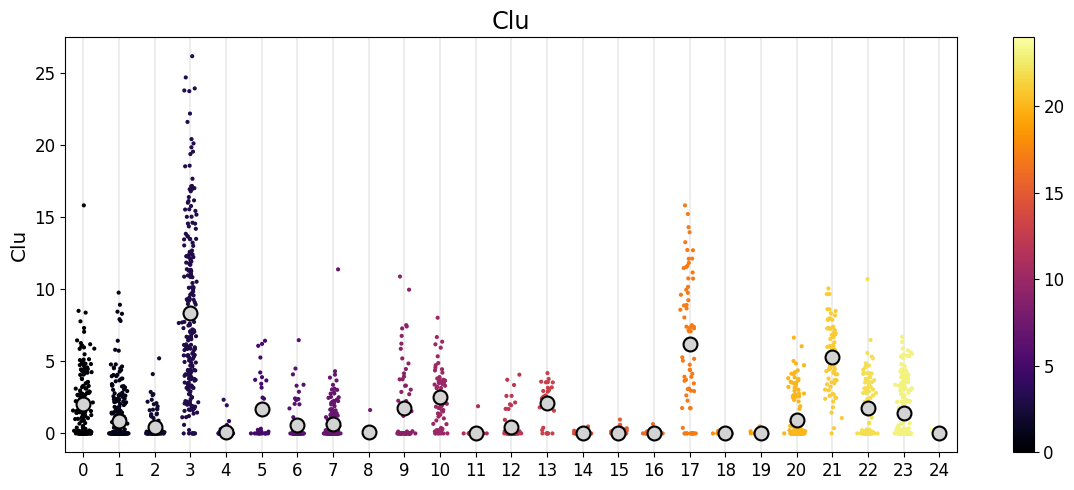

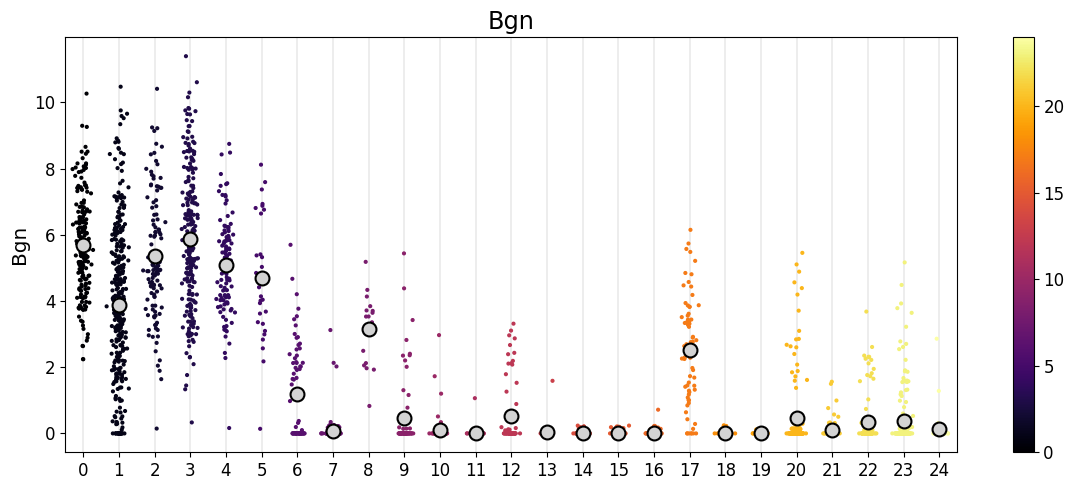

In [122]:
clusters = clusterings['Phenograph']

for curr_gene in ['Clu', 'Bgn']:
    curr_expression = scprep.select.select_cols(data, exact_word=curr_gene)
    scprep.plot.jitter(clusters, curr_expression, c=clusters, figsize=(12,5),
                           legend_anchor=(1,1), title=curr_gene)

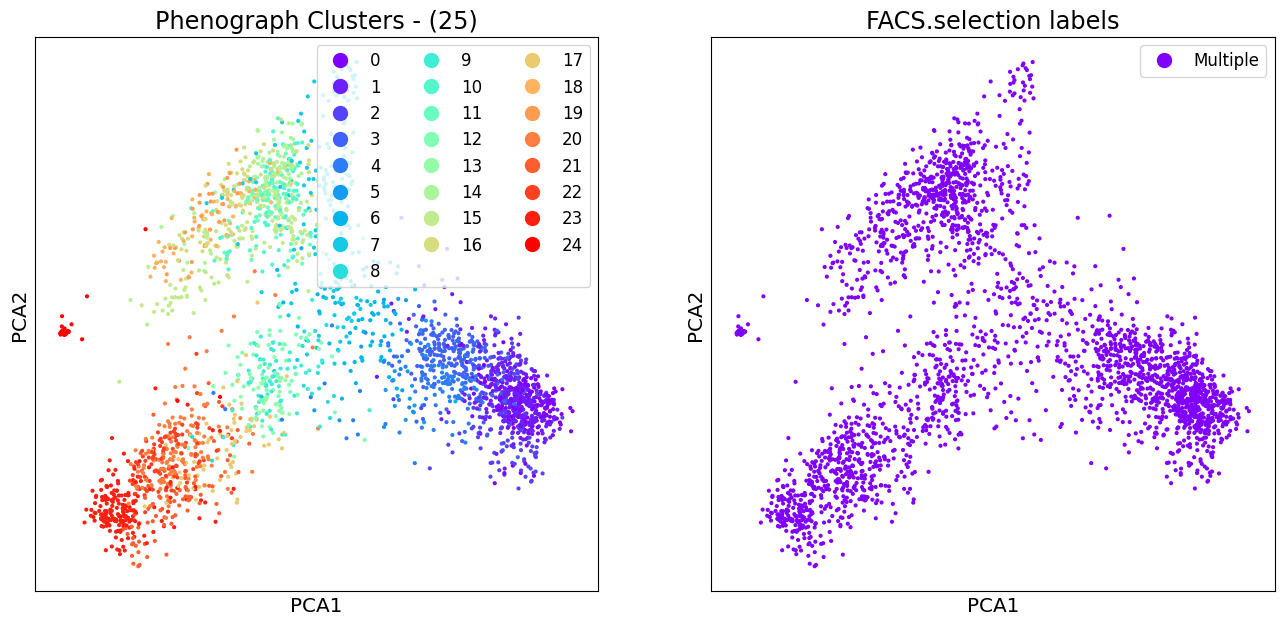

In [123]:
fig, axes = plt.subplots(1,2, figsize=(16,16), subplot_kw={'aspect':'equal'})

scprep.plot.scatter2d(data_pca, c=clusters, cmap=plt.cm.rainbow,
                     title='Phenograph Clusters - ({})'.format(len(np.unique(clusters))),
                     ticks=False, label_prefix="PCA", legend=True, discrete=True, ax=axes[0])

scprep.plot.scatter2d(data_pca, c=metadata['FACS.selection'], cmap=plt.cm.rainbow,
                         title='FACS.selection labels',
                         ticks=False, label_prefix="PCA", legend=True, discrete=True, ax=axes[1])

plt.show()

Top cluster index (by mean expression): 14
FACS.selection
Multiple    101
Name: count, dtype: int64


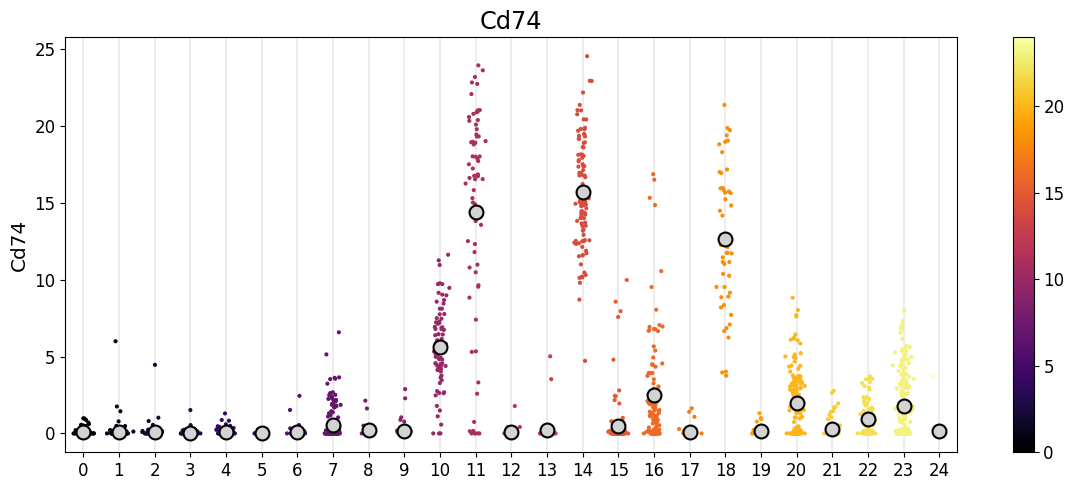

In [124]:
curr_gene = 'Cd74'
curr_expression = scprep.select.select_cols(data, exact_word=curr_gene)

scprep.plot.jitter(clusters, curr_expression, c=clusters, figsize=(12,5),
                       legend_anchor=(1,1), title=curr_gene)

top_cluster = np.argmax([curr_expression[clusters==c].mean().sum() for c in np.unique(clusters)])
print("Top cluster index (by mean expression):", top_cluster)
if 'FACS.selection' in metadata.columns:
    print(metadata.loc[clusters==top_cluster, 'FACS.selection'].value_counts())

In [125]:
data_sparse = scprep.utils.SparseDataFrame(data)

curr_cluster = 12
ttest_results = scprep.stats.differential_expression(data_sparse[clusters == curr_cluster],
                                                    data_sparse[clusters != curr_cluster],
                                                    measure='ttest')

top_genes = ttest_results['ttest'].abs().sort_values(ascending=False)
print("Top 20 differentially expressed genes by abs(ttest):")
print(top_genes.head(20))

Top 20 differentially expressed genes by abs(ttest):
Emp3             51.093560
Ly6a             46.065775
Ly6c1            37.534731
Cd44             36.515905
Gpx8             34.728128
Smad7            33.106414
Plscr1           31.564767
Ecm1             31.028574
Col6a3           30.990718
Vasn             30.738507
Serpinf1         30.591853
Lsp1             30.270264
2010002N04Rik    30.142684
Islr             29.998113
Dcn              29.080362
Slc6a6           28.791506
1190002H23Rik    28.584423
Mfap5            28.377819
Gfpt2            28.332635
Arid5a           28.058257
Name: ttest, dtype: float64


In [126]:
metadata['Phenograph_cluster'] = clusterings['Phenograph']
metadata['KMeans_cluster'] = clusterings['KMeans']
metadata['Spectral_cluster'] = clusterings['Spectral']
metadata.to_pickle('metadata_with_clusters.pickle.gz')
print("Saved metadata_with_clusters.pickle.gz")

Saved metadata_with_clusters.pickle.gz
